In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.validation import check_is_fitted
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('../data/raw/penguins_size.csv')
df['sex'] = df['sex'].replace('.', np.nan)   # мусорное значение из файла; безвредно, если его нет
df = df.dropna(subset=['body_mass_g'])        # пропуск в ЦЕЛИ не заполняют: строки без ответа бесполезны

TARGET = 'body_mass_g'
num_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm']
cat_cols = ['sex']

X = df[num_cols + cat_cols]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # tuning knob: доля теста
    random_state=42,     # tuning knob: фиксирует разбиение
)
print(X_train.shape, X_test.shape)   # ожидаю (273, 4) (69, 4)

(273, 4) (69, 4)


In [3]:
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):   # tuning knob: ширина границ
        self.factor = factor

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1 = np.nanpercentile(X, 25, axis=0)
        q3 = np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        return self

    def transform(self, X):
        check_is_fitted(self, ['lower_', 'upper_'])
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

In [4]:
num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('clip',   IQRClipper(factor=1.5)),
    ('scale',  StandardScaler()),   # для градиентного спуска масштабирование обязательно (лекция 4)
])
cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
    # drop='first' убирает один столбец, иначе столбцы пола в сумме дублируют свободный член
])
preprocess = ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)])

X_train_prep = preprocess.fit_transform(X_train)   # fit только на train
X_test_prep  = preprocess.transform(X_test)
y_train_np = y_train.to_numpy(dtype=float)
y_test_np  = y_test.to_numpy(dtype=float)

feat = num_cols + list(preprocess.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols))
print(X_train_prep.shape, X_test_prep.shape, feat)   # ожидаю (273, 5) (69, 5)

(273, 5) (69, 5) ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'sex_MALE', 'sex_unknown']


In [5]:
def add_bias(X):
    return np.c_[np.ones(len(X)), X]    # столбец единиц: его вес и есть w0 (свободный член)

def mse(w, Xb, y):
    return np.mean((y - Xb @ w) ** 2)   # MSE = (1/m) * Σ (y - ŷ)², где ŷ = Xb @ w

def grad(w, Xb, y):
    # ∇L = (2/m) * Xᵀ (ŷ - y): производная MSE по каждому w, все сразу в виде вектора
    return (2 / len(y)) * Xb.T @ (Xb @ w - y)

def gradient_descent(X, y, lr, n_iter):
    Xb = add_bias(X)
    w = np.zeros(Xb.shape[1])           # старт: все веса нулевые
    history = []
    for _ in range(n_iter):
        history.append(mse(w, Xb, y))   # сначала пишем потерю, потом делаем шаг
        w = w - lr * grad(w, Xb, y)     # та самая формула w := w − α·∇L(w)
    return w, history

# проверка градиента: аналитический против численного (разность вблизи точки)
Xb = add_bias(X_train_prep); w_t = np.random.default_rng(0).normal(size=Xb.shape[1]); eps = 1e-4
numeric = np.array([(mse(w_t + eps*e, Xb, y_train_np) - mse(w_t - eps*e, Xb, y_train_np)) / (2*eps)
                    for e in np.eye(len(w_t))])
assert np.allclose(numeric, grad(w_t, Xb, y_train_np), rtol=1e-4)
print('градиент верный')

градиент верный


In [6]:
w_gd, hist = gradient_descent(X_train_prep, y_train_np, lr=0.1, n_iter=1000)   # tuning knobs: lr, n_iter
sk = LinearRegression().fit(X_train_prep, y_train_np)

coef = pd.DataFrame({'свой GD': w_gd, 'sklearn': np.r_[sk.intercept_, sk.coef_]}, index=['intercept'] + feat)
coef['разность'] = coef['свой GD'] - coef['sklearn']
coef.round(2)

,свой GD,sklearn,разность
intercept,3955.54,3955.62,-0.08
culmen_length_mm,-3.36,-3.38,0.01
culmen_depth_mm,-174.43,-174.40,-0.03
flipper_length_mm,520.69,520.74,-0.05
sex_MALE,532.37,532.26,0.11
sex_unknown,136.66,135.56,1.10


In [7]:
def metrics(y_true, y_pred):
    return {'MAE, г': mean_absolute_error(y_true, y_pred),
            'RMSE, г': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R²': r2_score(y_true, y_pred)}

pd.DataFrame({'свой GD': metrics(y_test_np, add_bias(X_test_prep) @ w_gd),
              'sklearn': metrics(y_test_np, sk.predict(X_test_prep))}).round(3)

,свой GD,sklearn
"MAE, г",266.326,266.298
"RMSE, г",323.305,323.286
R²,0.843,0.843


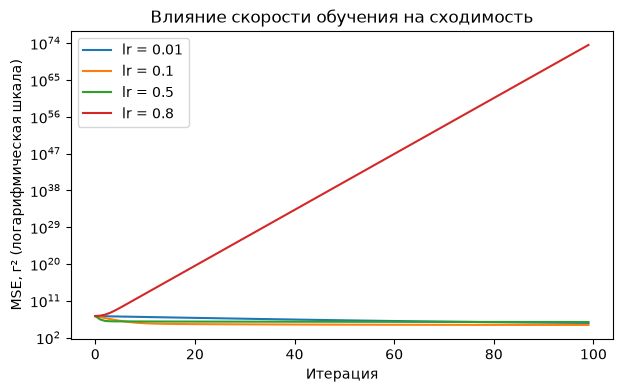

In [8]:
plt.figure(figsize=(7, 4))
for lr in [0.01, 0.1, 0.5, 0.8]:   # tuning knob: набор скоростей (требуется минимум три)
    _, h = gradient_descent(X_train_prep, y_train_np, lr=lr, n_iter=100)
    plt.plot(h, label=f'lr = {lr}')
plt.yscale('log')   # потеря меняется на порядки, на обычной шкале видна одна линия
plt.xlabel('Итерация'); plt.ylabel('MSE, г² (логарифмическая шкала)')
plt.title('Влияние скорости обучения на сходимость'); plt.legend(); plt.show()

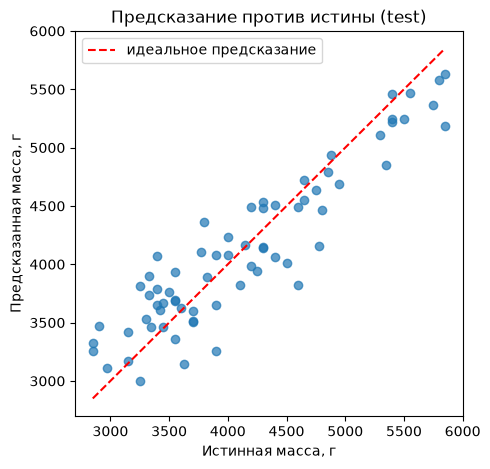

In [9]:
y_pred = sk.predict(X_test_prep)
plt.figure(figsize=(5, 5))
plt.scatter(y_test_np, y_pred, alpha=0.7)
lims = [y_test_np.min(), y_test_np.max()]
plt.plot(lims, lims, 'r--', label='идеальное предсказание')
plt.xlabel('Истинная масса, г'); plt.ylabel('Предсказанная масса, г')
plt.title('Предсказание против истины (test)'); plt.legend(); plt.show()